Распределение Пуассона: P(X = k) = a^k * e^(-a) / k!
k	a=0.8	a=1.5	a=3
0	0.4493	0.2231	0.0498
1	0.3595	0.3347	0.1494
2	0.1438	0.2510	0.2240
3	0.0383	0.1255	0.2240
4	0.0077	0.0471	0.1680
5	0.0012	0.0141	0.1008
6	0.0002	0.0035	0.0504
7	0.0000	0.0008	0.0216

Геометрическое распределение: P(X = k) = γ(1-γ)^k
k	γ=0.9	γ=0.8	γ=0.5
0	0.9000	0.8000	0.5000
1	0.0900	0.1600	0.2500
2	0.0090	0.0320	0.1250
3	0.0009	0.0064	0.0625
4	0.0001	0.0013	0.0312
5	0.0000	0.0003	0.0156
6	0.0000	0.0001	0.0078
7	0.0000	0.0000	0.0039


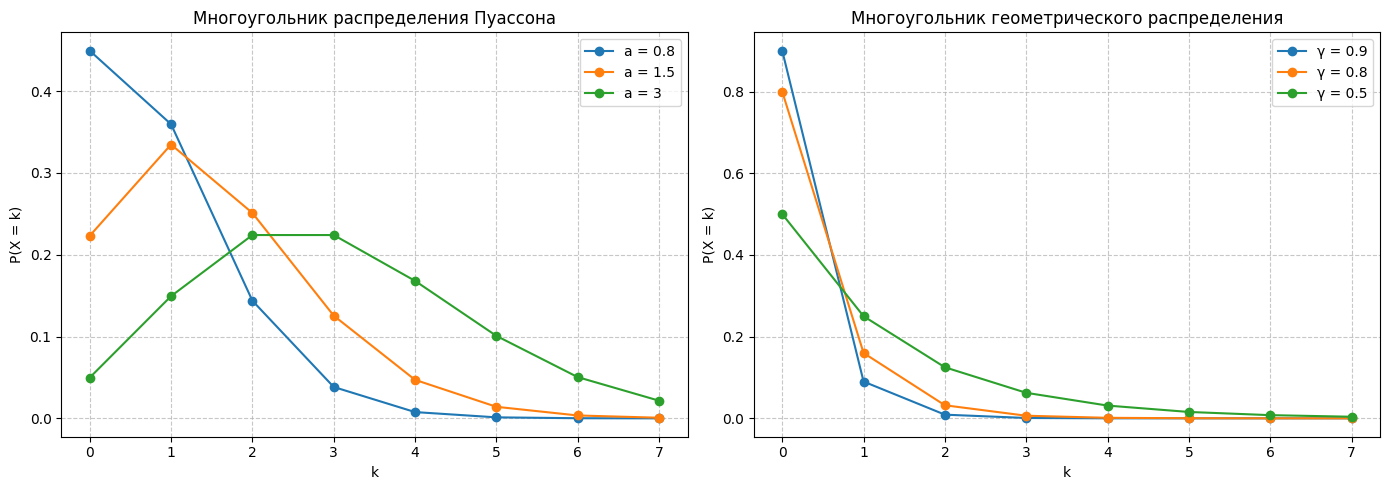

In [7]:
import math
import numpy as np
import matplotlib.pyplot as plt

# Параметры из методички
poisson_a = [0.8, 1.5, 3]          # параметры a для Пуассона
geom_gamma = [0.9, 0.8, 0.5]     # параметры γ для геометрического

# Диапазоны значений k
k_pois = np.arange(0, 8)        # для Пуассона достаточно 0..10
k_geom = np.arange(0, 8)        # для геометрического 0..15

# Функции вероятностей
def poisson_pmf(k, a):
    """P(X = k) для распределения Пуассона"""
    return (a ** k) * math.exp(-a) / math.factorial(k)

def geom_pmf(k, gamma):
    """P(X = k) для геометрического распределения p_k = γ(1-γ)^k"""
    return gamma * (1 - gamma) ** k

# Расчёт вероятностей
pois_probs = {a: [poisson_pmf(k, a) for k in k_pois] for a in poisson_a}
geom_probs = {g: [geom_pmf(k, g) for k in k_geom] for g in geom_gamma}

# Вывод таблиц
print("Распределение Пуассона: P(X = k) = a^k * e^(-a) / k!")
print("k\t" + "\t".join(f"a={a}" for a in poisson_a))
for i, k in enumerate(k_pois):
    print(f"{k}\t" + "\t".join(f"{pois_probs[a][i]:.4f}" for a in poisson_a))

print("\nГеометрическое распределение: P(X = k) = γ(1-γ)^k")
print("k\t" + "\t".join(f"γ={g}" for g in geom_gamma))
for i, k in enumerate(k_geom):
    print(f"{k}\t" + "\t".join(f"{geom_probs[g][i]:.4f}" for g in geom_gamma))

# Построение графиков
plt.rcParams['font.family'] = 'DejaVu Sans'   # поддержка кириллицы
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Пуассон ---
for a in poisson_a:
    axes[0].plot(k_pois, pois_probs[a], marker='o', label=f'a = {a}')
axes[0].set_title('Многоугольник распределения Пуассона')
axes[0].set_xlabel('k')
axes[0].set_ylabel('P(X = k)')
axes[0].grid(True, linestyle='--', alpha=0.7)
axes[0].legend()

# --- Геометрическое ---
for g in geom_gamma:
    axes[1].plot(k_geom, geom_probs[g], marker='o', label=f'γ = {g}')
axes[1].set_title('Многоугольник геометрического распределения')
axes[1].set_xlabel('k')
axes[1].set_ylabel('P(X = k)')
axes[1].grid(True, linestyle='--', alpha=0.7)
axes[1].legend()

plt.tight_layout()
plt.show()

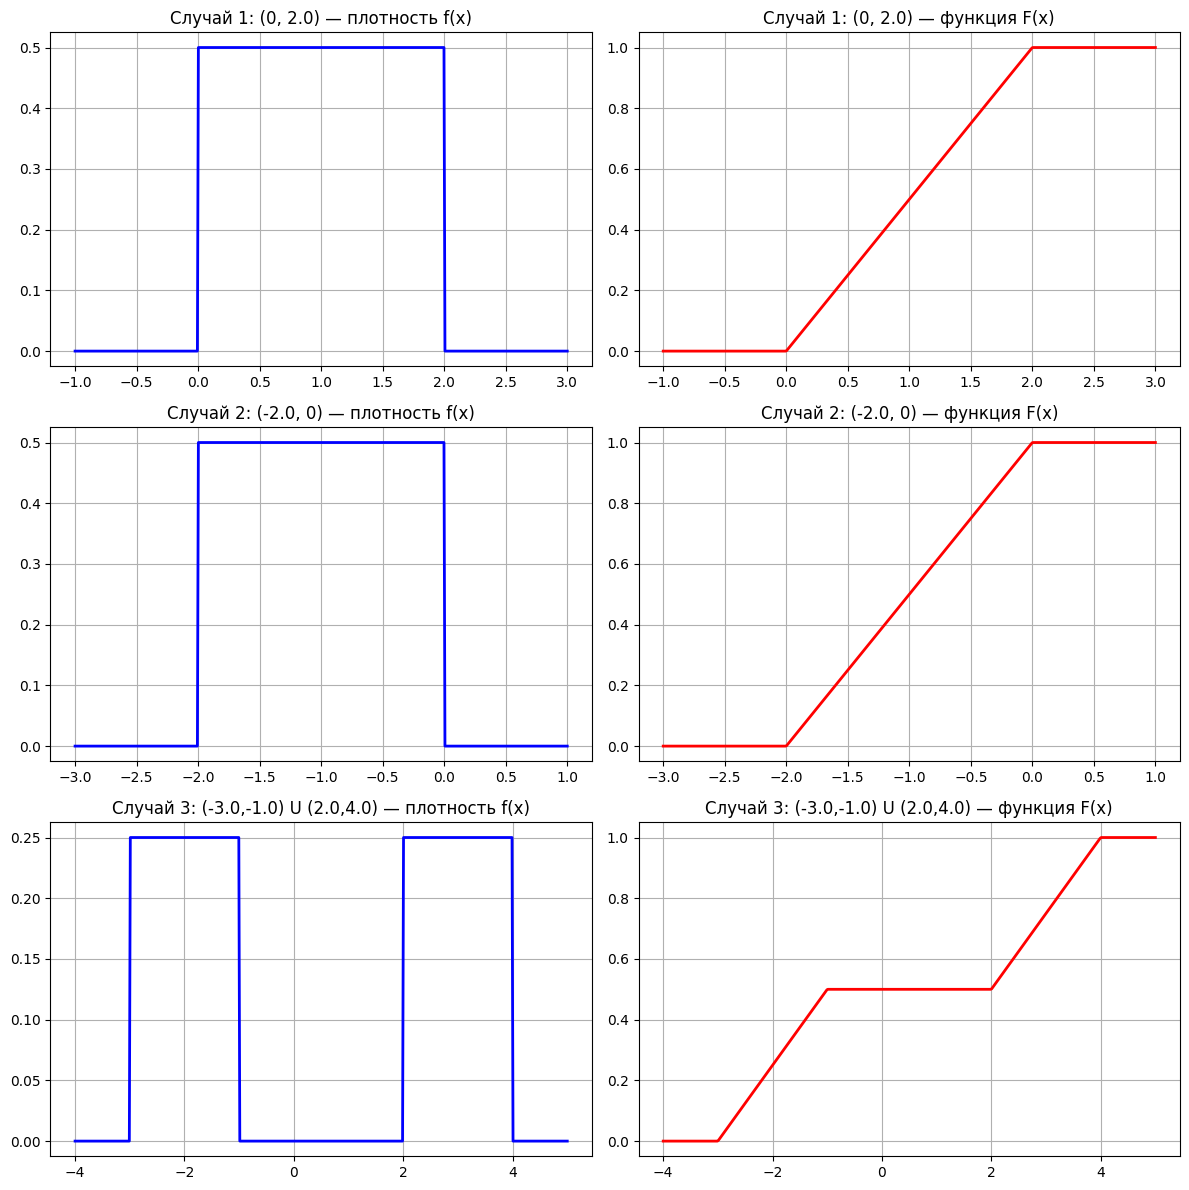

Случай 1: (0, b)
M = 1.0000, α2 = 1.3333, D = 0.3333, σ = 0.5774, ν = 0.5774

Случай 2: (a, 0)
M = 0.6667, α2 = 0.5926, D = 0.1481, σ = -0.3849, ν = -0.5774

Случай 3: (a,b) U (c,d)
M = 0.5000, α2 = 6.8333, D = 6.5833, σ = 2.5658, ν = 5.1316


In [1]:
import numpy as np
import matplotlib.pyplot as plt


# ---------- Вспомогательные функции ----------
def uniform_pdf(x, a, b):
    return np.where((x >= a) & (x <= b), 1.0 / (b - a), 0.0)


def uniform_cdf(x, a, b):
    return np.where(x <= a, 0.0, np.where(x >= b, 1.0, (x - a) / (b - a)))


def union_pdf(x, a, b, c, d):
    L1 = b - a
    L2 = d - c
    L = L1 + L2
    return np.where(((x >= a) & (x <= b)) | ((x >= c) & (x <= d)), 1.0 / L, 0.0)


def union_cdf(x, a, b, c, d):
    L1 = b - a
    L2 = d - c
    L = L1 + L2
    y = np.zeros_like(x)
    mask1 = (x > a) & (x < b)
    y[mask1] = (x[mask1] - a) / L
    mask2 = (x >= b) & (x <= c)
    y[mask2] = L1 / L
    mask3 = (x > c) & (x < d)
    y[mask3] = (L1 + (x[mask3] - c)) / L
    y[x >= d] = 1.0
    return y


# ---------- Параметры примеров ----------
b1 = 2.0  # случай 1: (0, b1)
a2 = -2.0  # случай 2: (a2, 0)
a3, b3, c3, d3 = -3.0, -1.0, 2.0, 4.0  # случай 3: (a3,b3) U (c3,d3)

# ---------- Сетки значений x ----------
x1 = np.linspace(-1, 3, 500)
x2 = np.linspace(-3, 1, 500)
x3 = np.linspace(-4, 5, 500)

# ---------- Построение графиков ----------
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

# Случай 1
axes[0, 0].plot(x1, uniform_pdf(x1, 0, b1), "b-", lw=2)
axes[0, 0].set_title(f"Случай 1: (0, {b1}) — плотность f(x)")
axes[0, 0].grid(True)
axes[0, 1].plot(x1, uniform_cdf(x1, 0, b1), "r-", lw=2)
axes[0, 1].set_title(f"Случай 1: (0, {b1}) — функция F(x)")
axes[0, 1].grid(True)

# Случай 2
axes[1, 0].plot(x2, uniform_pdf(x2, a2, 0), "b-", lw=2)
axes[1, 0].set_title(f"Случай 2: ({a2}, 0) — плотность f(x)")
axes[1, 0].grid(True)
axes[1, 1].plot(x2, uniform_cdf(x2, a2, 0), "r-", lw=2)
axes[1, 1].set_title(f"Случай 2: ({a2}, 0) — функция F(x)")
axes[1, 1].grid(True)

# Случай 3
axes[2, 0].plot(x3, union_pdf(x3, a3, b3, c3, d3), "b-", lw=2)
axes[2, 0].set_title(f"Случай 3: ({a3},{b3}) U ({c3},{d3}) — плотность f(x)")
axes[2, 0].grid(True)
axes[2, 1].plot(x3, union_cdf(x3, a3, b3, c3, d3), "r-", lw=2)
axes[2, 1].set_title(f"Случай 3: ({a3},{b3}) U ({c3},{d3}) — функция F(x)")
axes[2, 1].grid(True)

plt.tight_layout()
plt.show()


# ---------- Расчёт числовых характеристик ----------
def stats_uniform(a, b):
    M = (a + b) / 2.0
    alpha2 = (a**2 + a * b + b**2) / 3.0
    D = (b - a) ** 2 / 12.0
    sigma = (b - a) / (2.0 * np.sqrt(3.0))
    nu = sigma / M if M != 0 else np.nan
    return M, alpha2, D, sigma, nu


print("Случай 1: (0, b)")
M, a2, D, sigma, nu = stats_uniform(0, b1)
print(f"M = {M:.4f}, α2 = {a2:.4f}, D = {D:.4f}, σ = {sigma:.4f}, ν = {nu:.4f}")

print("\nСлучай 2: (a, 0)")
M, a2, D, sigma, nu = stats_uniform(a2, 0)
print(f"M = {M:.4f}, α2 = {a2:.4f}, D = {D:.4f}, σ = {sigma:.4f}, ν = {nu:.4f}")

print("\nСлучай 3: (a,b) U (c,d)")
L1 = b3 - a3
L2 = d3 - c3
L = L1 + L2
M = (L1 * (a3 + b3) / 2 + L2 * (c3 + d3) / 2) / L
alpha2 = ((b3**3 - a3**3) / 3 + (d3**3 - c3**3) / 3) / L
D = alpha2 - M**2
sigma = np.sqrt(D)
nu = sigma / M if M != 0 else np.nan
print(f"M = {M:.4f}, α2 = {alpha2:.4f}, D = {D:.4f}, σ = {sigma:.4f}, ν = {nu:.4f}")